In [11]:
!ls -lh online_retail.csv

-rw-r--r-- 1 root root 47M Nov 15 13:10 online_retail.csv


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("online_retail.csv", encoding="ISO-8859-1")
print("Shape:", df.shape)
print("Missing CustomerID:", df["CustomerID"].isnull().sum())

Shape: (541909, 8)
Missing CustomerID: 135080


In [13]:
df_raw = df.copy()

# Remove rows with no customer ID or other missing key values
df = df.dropna(subset=["CustomerID", "Quantity", "InvoiceDate", "UnitPrice"])

# Remove cancelled orders (invoice numbers starting with C)
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Remove zero or negative quantities and prices
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# Fix data types
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = df["CustomerID"].astype(int).astype(str)

# Money spent on each row
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print("Rows before:", len(df_raw), "| Rows after:", len(df))
print("Customers:", df["CustomerID"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Rows before: 541909 | Rows after: 397884
Customers: 4338
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


**Cleaning notes:** Removed 135,080 rows with no CustomerID (cannot group unknown customers), cancelled orders (invoice starting with "C") and rows with zero or negative quantity or price. Converted InvoiceDate to a date and CustomerID to text. Result: 397,884 rows and 4,338 customers.

In [14]:
# Reference date = one day after the last purchase in the data
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

print(rfm.describe().round(1))
print()
print("Average purchase value per order:", round(df.groupby("InvoiceNo")["TotalPrice"].sum().mean(), 2))

       Recency  Frequency  Monetary
count   4338.0     4338.0    4338.0
mean      92.5        4.3    2054.3
std      100.0        7.7    8989.2
min        1.0        1.0       3.8
25%       18.0        1.0     307.4
50%       51.0        2.0     674.5
75%      142.0        5.0    1661.7
max      374.0      209.0  280206.0

Average purchase value per order: 480.87


**Observations (RFM):**
- A typical customer last bought about 51 days ago (median) and has placed 2 orders, spending about 675 in total. The average order is worth 480.87.
- The averages are much higher than the medians (for example, Monetary 2,054 vs 675), because a few very large customers (max 280,206) pull them up. Most customers are small buyers.

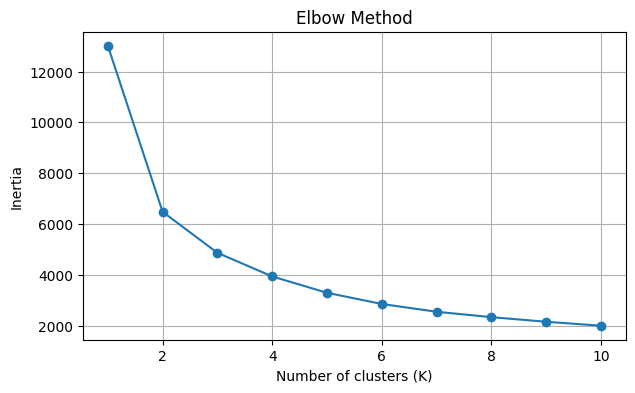

In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Log transform to reduce the effect of very large values
rfm_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

# Scale all three to the same range
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Elbow method: try 1 to 10 groups
inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

**Elbow method:** Inertia falls steeply up to 3-4 clusters and flattens after K = 4, so I chose K = 4 clusters.

         Recency  Frequency  Monetary  Customers
Cluster                                         
0           18.1        2.1     551.8        837
1           12.1       13.7    8074.3        716
2           71.1        4.1    1802.8       1173
3          182.5        1.3     343.5       1612


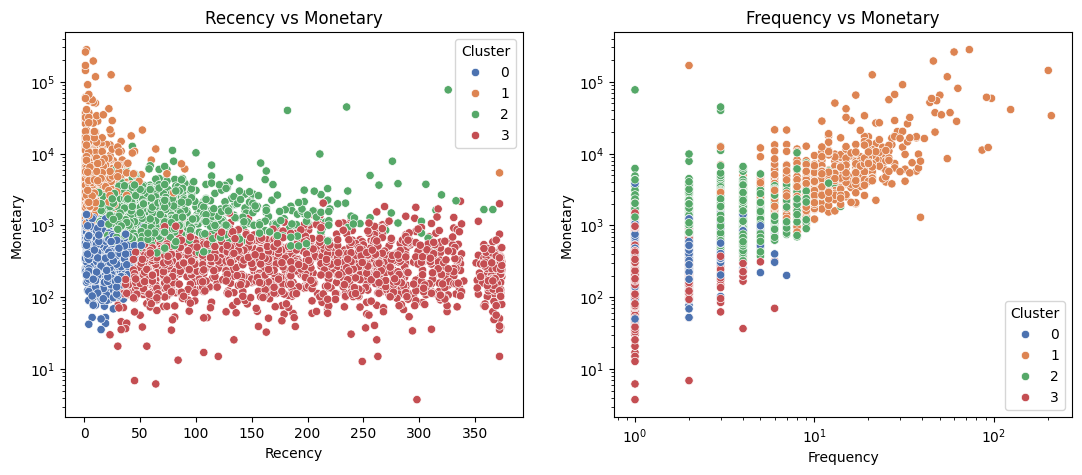

/tmp/ipykernel_1889/251084294.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=rfm, x="Cluster", palette="deep")


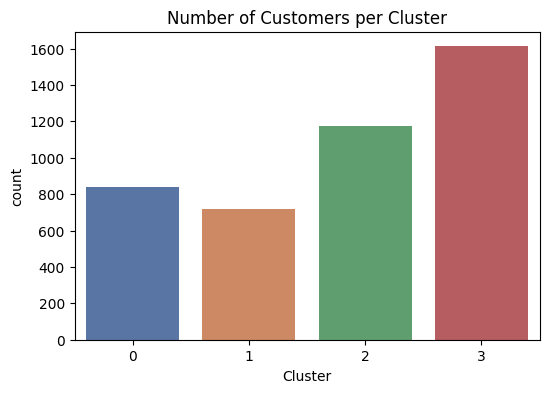

In [16]:
# Run K-Means with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Profile each cluster (average values + size)
profile = rfm.groupby("Cluster").agg(
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    Customers=("CustomerID", "count")
).round(1)
print(profile)

# Scatter plots (2 feature combinations)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=rfm, x="Recency", y="Monetary", hue="Cluster", palette="deep", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Recency vs Monetary")
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Cluster", palette="deep", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Frequency vs Monetary")
plt.show()

# Bar chart: customers per cluster
plt.figure(figsize=(6, 4))
sns.countplot(data=rfm, x="Cluster", palette="deep")
plt.title("Number of Customers per Cluster")
plt.show()

## Cluster Profiles and Marketing Recommendations

- **Cluster 1: Champions (716 customers).** Bought very recently (about 12 days ago), order often (about 14 orders) and spend the most (about 8,074 each). Recommendation: reward them with a VIP or loyalty programme and early access to new products. Don't discount heavily, since they already buy.
- **Cluster 2: Loyal regulars (1,173 customers).** Bought about 71 days ago, with about 4 orders and about 1,883 spent. Recommendation: send reminders and bundle offers to move them towards Champions.
- **Cluster 0: Recent newcomers (837 customers).** Bought recently (about 18 days ago) but only about 2 orders and about 552 spent. Recommendation: send a welcome series and a second-purchase offer to turn them into repeat buyers.
- **Cluster 3: Lapsed customers (1,612 customers, the largest group).** Last bought about 183 days ago, with about 1 order and about 344 spent. Recommendation: run win-back campaigns with a discount to bring them back before they are lost.

**Key insight:** The 716 Champions are only about 17% of customers but spend by far the most per customer, so protecting them matters most. The largest group (37%) is lapsed customers, so win-back campaigns offer the biggest room to grow.